In [2]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

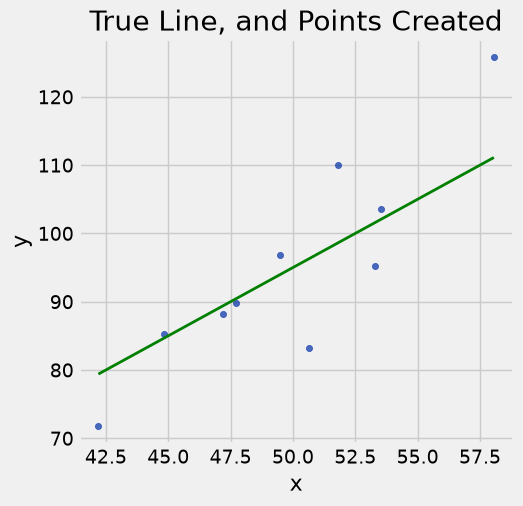

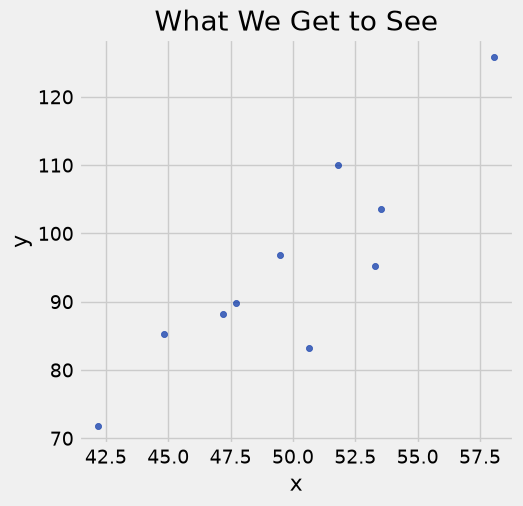

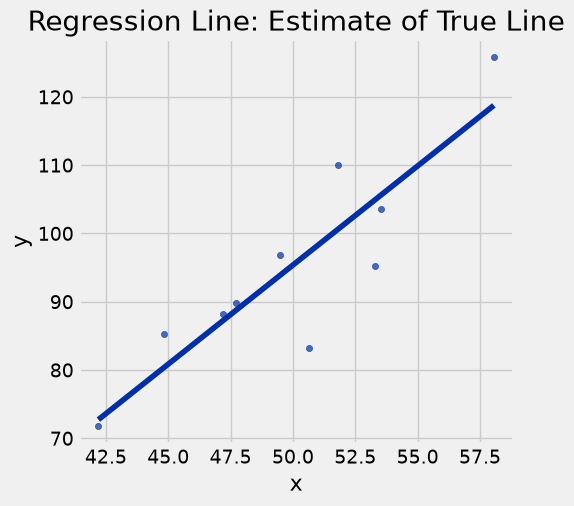

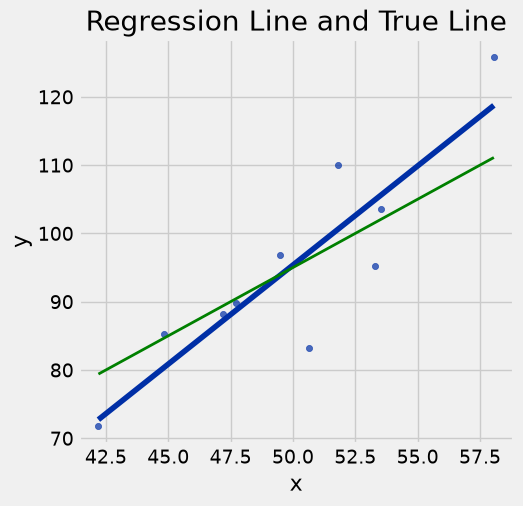

In [4]:
def draw_and_compare(true_slope, true_int, sample_size):
    x = np.random.normal(50, 5, sample_size)
    xlims = np.array([np.min(x), np.max(x)])
    errors = np.random.normal(0, 6, sample_size)
    y = (true_slope * x + true_int) + errors
    sample = Table().with_columns('x', x, 'y', y)

    sample.scatter('x', 'y')
    plt.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plt.title('True Line, and Points Created')

    sample.scatter('x', 'y')
    plt.title('What We Get to See')

    sample.scatter('x', 'y', fit_line=True)
    plt.title('Regression Line: Estimate of True Line')

    sample.scatter('x', 'y', fit_line=True)
    plt.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plt.title("Regression Line and True Line")

draw_and_compare(true_slope=2, true_int=-5, sample_size=10)

# Regression Prediction

In [5]:
def standard_units(arr):
    return (arr - np.average(arr))/np.std(arr)

def correlation(t, x, y):
    x_standard = standard_units(t.column(x))
    y_standard = standard_units(t.column(y))
    return np.average(x_standard * y_standard)

def slope(t, x, y):
    r = correlation(t, x, y)
    y_sd = np.std(t.column(y))
    x_sd = np.std(t.column(x))
    return r * y_sd / x_sd

def intercept(t, x, y):
    x_mean = np.mean(t.column(x))
    y_mean = np.mean(t.column(y))
    return y_mean - slope(t, x, y)*x_mean

def fitted_values(t, x, y):
    """Return an array of the regression estimates at all the x values"""
    m = slope(t, x, y)
    b = intercept(t, x, y)
    return m*t.column(x) + b

def residuals(t, x, y):
    """Return an array of all the residuals"""
    predictions = fitted_values(t, x, y)
    return t.column(y) - predictions

In [6]:
births = Table.read_table('data/baby.csv')
births

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


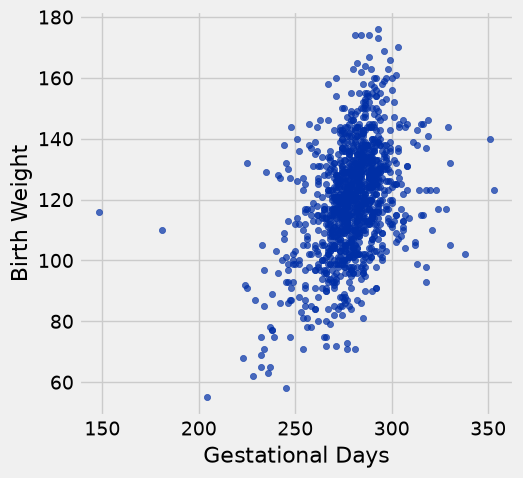

In [7]:
births.scatter('Gestational Days', 'Birth Weight')

In [8]:
correlation(births, 'Gestational Days', 'Birth Weight')

0.40754279338885108

In [9]:
# According to the CDC, preterm and postterm pregnancy cutoffs
37 * 7, 42 * 7

(259, 294)

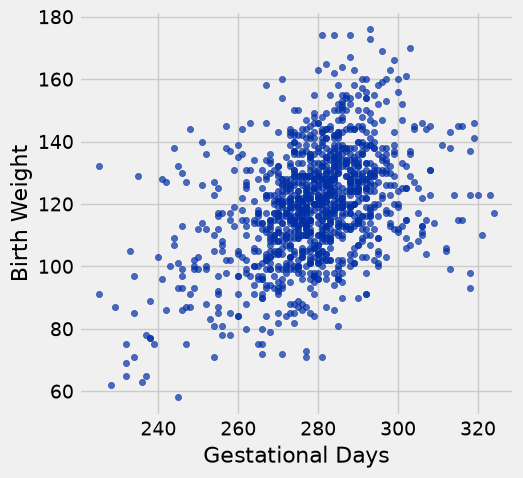

In [13]:
births = births.where('Gestational Days', are.between(225, 325))
births.scatter('Gestational Days', 'Birth Weight')

In [14]:
correlation(births, 'Gestational Days', 'Birth Weight')

0.42295118452423991

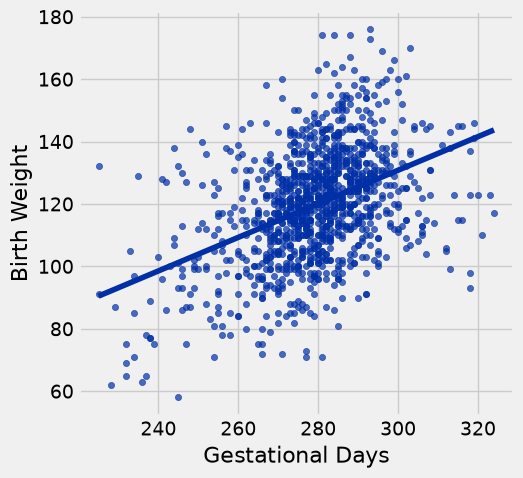

In [15]:
births.scatter('Gestational Days', 'Birth Weight', fit_line=True)

In [16]:
# Goal: can we estimate the *true* relationship between x and y?

In [17]:
slope(births, 'Gestational Days', 'Birth Weight')

0.53784536766790358

Slope of regression line: 0.538
Approximate 95%-confidence interval for the slope of the true line:
0.46 to 0.617


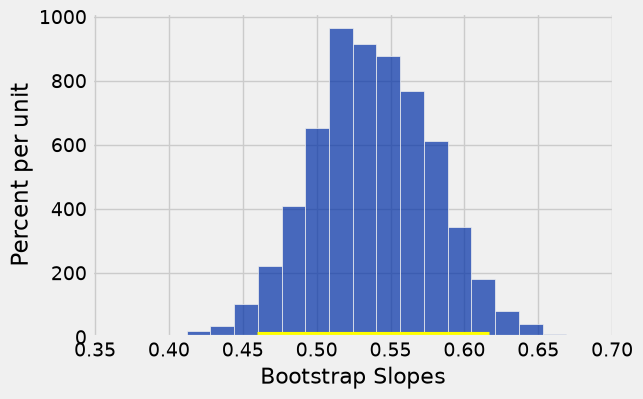

In [18]:
repetitions = 2500

# create 2500 bootstrap samples, find the slopes, and save them all
slopes = make_array()
for i in np.arange(repetitions):
    bootstrap_sample = births.sample()
    bootstrap_slope = slope(bootstrap_sample, 'Gestational Days', 'Birth Weight')
    slopes = np.append(slopes, bootstrap_slope)

# find the endpoints of a 95% confidence interval for the true slope
left = percentile(2.5, slopes)
right = percentile(97.5, slopes)

# slope of the regression line from the original sample
observed_slope = slope(births, 'Gestational Days', 'Birth Weight')

# Display results (you don't have to understand this code)
Table().with_column('Bootstrap Slopes', slopes).hist(bins=20)
plt.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=8);
print('Slope of regression line:', round(observed_slope, 3))
print('Approximate 95%-confidence interval for the slope of the true line:')
print(round(left, 3), 'to', round(right, 3))

In [21]:
def bootstrap_slope_interval(t, x, y, repetitions=2500):
    # create repetitions # of bootstrap samples, find the slopes, and save them all
    slopes = make_array()
    for i in np.arange(repetitions):
        bootstrap_sample = t.sample()
        bootstrap_slope = slope(bootstrap_sample, x, y)
        slopes = np.append(slopes, bootstrap_slope)
    
    # find the endpoints of a 95% confidence interval for the true slope
    left = percentile(2.5, slopes)
    right = percentile(97.5, slopes)
    
    # slope of the regression line from the original sample
    observed_slope = slope(t, x, y)
    
    # Display results (you don't have to understand this code)
    Table().with_column('Bootstrap Slopes', slopes).hist(bins=20)
    plt.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=8);
    print('Slope of regression line:', round(observed_slope, 3))
    print('Approximate 95%-confidence interval for the slope of the true line:')
    print(round(left, 3), 'to', round(right, 3))

Slope of regression line: 0.538
Approximate 95%-confidence interval for the slope of the true line:
0.459 to 0.617


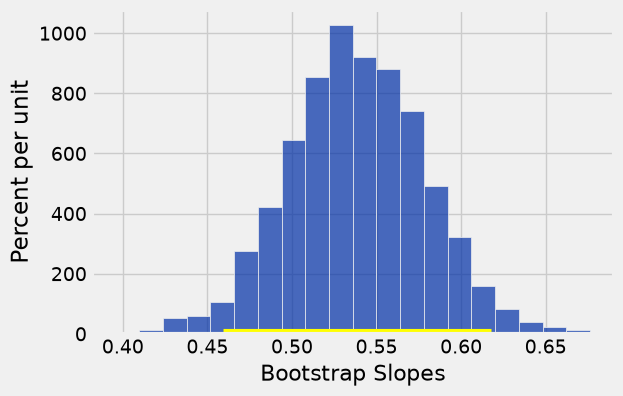

In [22]:
bootstrap_slope_interval(births, 'Gestational Days', 'Birth Weight', 3000)